In [ ]:
import pandas as pd
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
df = pd.read_csv('/content/gdrive/MyDrive/Copy of salary_data.csv')

In [ ]:
df.head()

,Age,Experience,Education,Job_Role,City,Salary
0,42,15,Bachelor,Data Scientist,Noida,1916541
1,38,17,Bachelor,Data Scientist,Chennai,2196338
2,24,3,Bachelor,AI Engineer,Delhi,1219746
3,41,11,Bachelor,Business Analyst,Delhi,1305808
4,29,8,Master,AI Engineer,Indore,1793937


In [ ]:
df.tail()

,Age,Experience,Education,Job_Role,City,Salary
995,25,0,Master,AI Architect,Indore,1194365
996,39,3,Master,ML Engineer,Pune,1144974
997,30,0,PhD,Data Scientist,Pune,1043172
998,36,8,Bachelor,Data Scientist,Indore,1310213
999,32,9,Bachelor,ML Engineer,Chennai,1557878


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Age         1000 non-null   int64 
 1   Experience  1000 non-null   int64 
 2   Education   1000 non-null   object
 3   Job_Role    1000 non-null   object
 4   City        1000 non-null   object
 5   Salary      1000 non-null   int64 
dtypes: int64(3), object(3)
memory usage: 47.0+ KB


In [ ]:
df.describe()

,Age,Experience,Salary
count,1000.000000,1000.000000,1.000000e+03
mean,33.495000,7.558000,1.404002e+06
std,6.828807,5.371358,5.628025e+05
min,22.000000,0.000000,2.500000e+05
25%,28.000000,3.000000,9.531775e+05
50%,34.000000,7.000000,1.362396e+06
75%,39.000000,12.000000,1.767518e+06
max,45.000000,20.000000,3.179172e+06


In [ ]:
df.isnull().sum()

,0
Age,0
Experience,0
Education,0
Job_Role,0
City,0
Salary,0


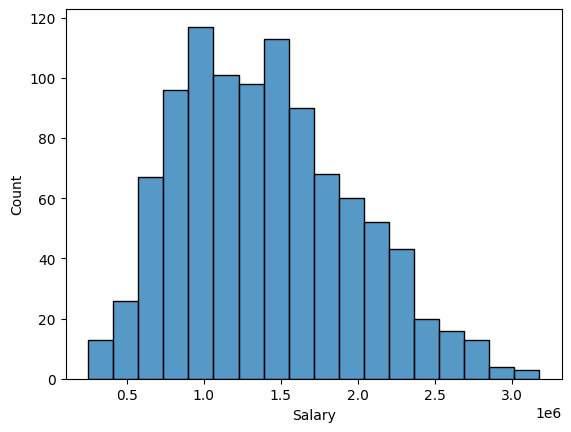

In [ ]:
import matplotlib.pyplot as plt
sns.histplot(df['Salary'])
plt.show()

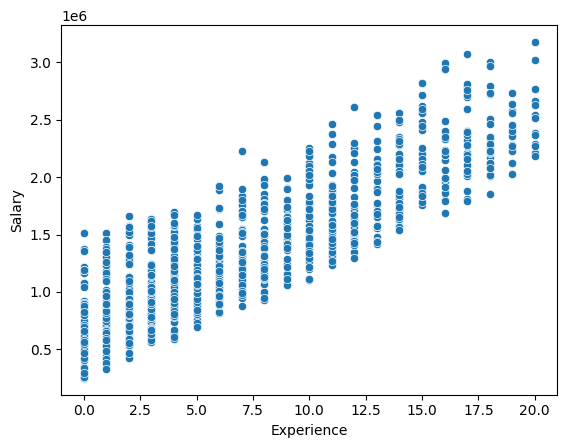

In [ ]:
sns.scatterplot(
    x='Experience',
    y='Salary',
    data=df
)
plt.show()

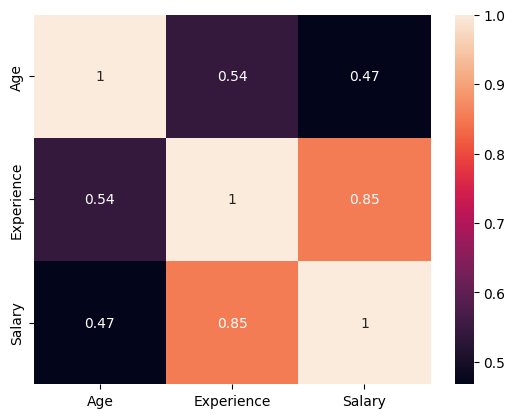

In [ ]:
sns.heatmap(df.corr(numeric_only=True),
            annot=True)
plt.show()

In [ ]:
import sklearn
from sklearn.preprocessing import LabelEncoder


In [ ]:
le_edu = LabelEncoder()
le_role = LabelEncoder()
le_city = LabelEncoder()

df['Education'] = le_edu.fit_transform(df['Education'])
df['Job_Role'] = le_role.fit_transform(df['Job_Role'])
df['City'] = le_city.fit_transform(df['City'])


In [ ]:
df.head()

,Age,Experience,Education,Job_Role,City,Salary
0,42,15,0,5,7,1916541
1,38,17,0,5,2,2196338
2,24,3,0,1,3,1219746
3,41,11,0,2,3,1305808
4,29,8,1,1,5,1793937


In [ ]:
X = df.drop('Salary',axis =1)
y = df['Salary']


In [ ]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
X_train

,Age,Experience,Education,Job_Role,City
29,33,12,0,6,6
535,23,2,1,6,1
695,43,18,0,2,3
557,35,14,0,4,3
836,32,11,1,3,8
...,...,...,...,...,...
106,36,3,1,5,1
270,41,17,1,5,8
860,40,14,0,0,8
435,36,15,1,6,7


In [ ]:
X_test

,Age,Experience,Education,Job_Role,City
521,22,1,1,2,6
737,23,2,1,3,3
740,39,17,1,5,2
660,39,0,0,5,0
411,22,0,1,5,4
...,...,...,...,...,...
408,25,4,1,6,6
332,34,11,1,6,3
208,27,6,1,0,0
613,22,1,1,6,3


In [ ]:
y_train

,Salary
29,1639045
535,925591
695,2016068
557,1698937
836,1433335
...,...
106,934462
270,2320191
860,2500956
435,2256049


In [ ]:
y_test

,Salary
521,722930
737,535425
740,2155029
660,493368
411,816797
...,...
408,1210317
332,1934612
208,1727483
613,945976


In [ ]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train,y_train)

LinearRegression()

In [ ]:
lr_pred = lr_model.predict(X_test)
print(lr_pred)

[ 936051.45036819  976477.89042713 2191383.98438277  547651.35943905
  680178.14549929 2201545.8873903   915149.38941857 1786719.98100555
 1146566.08945766 1391887.20444578 2384040.8300092  1317292.94297358
  840100.0776906  2270457.40028789  762865.53606497 2105420.44772776
 2174158.68250804 1388832.43094409 1037921.02764027  692932.23418992
  841186.63005058 1668950.48458618 1262166.82427511 2256958.95164021
 1312695.75727485 1181082.24545728 1829796.23846258 1110056.24903882
 1772075.5492175  1275142.28555336 1780577.00876218 1249705.84403299
  737202.54854399  986413.24743405 1544789.66902497 1639259.04977001
 2003952.45221169 1148350.70636976 1256023.87274539 1347664.98456204
 1291792.70684113  804729.24793375 1533886.75969434  605810.40931405
  635901.66824815 1020408.80092775  822648.25052891  568374.96885839
 2238527.2670743  2131542.64871975 1202033.39036132 2138719.71502108
 1543870.23188523  929675.78994079 1575292.04695975 1770695.88840901
 1066627.4937802  1435240.87020958

In [ ]:
from sklearn.metrics import r2_score

score = r2_score(y_test,lr_pred)
print(score)

0.8308413832425301


In [ ]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test,lr_pred)
print(mae)

211742.77122498714


In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor()
dt_model.fit(X_train,y_train)

DecisionTreeRegressor()

In [ ]:
dt_pred = dt_model.predict(X_test)
print(dt_pred)

[ 638941.          660696.         2199702.          619658.
  753619.         1994623.         1133157.         1837078.
  801770.         1651308.         2210772.         1328901.
  743678.         2350395.          743678.         2106007.
 2403246.         1033742.         1007471.          773811.
  832166.         1975056.         1070891.         2241196.
 1328901.         1604847.         1234717.         1092605.
 1423775.          950208.         1439376.         1313416.
  742610.         1329230.         1629677.         1150667.
 1691533.         1396518.         1420821.         1396926.
 1396926.          965404.66666667 2024069.          625093.
  975288.          802422.         1164943.          577688.
 2190193.         1808642.         1122700.         2576277.
 1629677.          832166.         1829673.         1439376.
 1369661.         1040612.         1259062.         1691533.
 1097413.          661683.          882812.         2251628.
 2135086.          75101

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor()
rf_model.fit(X_train,y_train)

RandomForestRegressor()

In [ ]:
rf_pred = rf_model.predict(X_test)
print(rf_pred)

[ 589902.07        692384.15       2192427.15        674995.49
  789194.34       2006749.5        1195225.1275     1872529.87
  820707.67       1544218.14       2157386.2        1400589.0402381
  864558.43       2318311.63        842588.35       2145436.1
 2260636.61       1051694.22166667 1057898.08        676187.825
  822324.75       1928131.4        1188149.62       2268289.19
 1388674.27190476 1447633.81       1376910.15       1209832.85
 1405166.82        950355.54       1532010.63       1273021.4
  748103.93       1292250.74       1640228.16       1150925.23266667
 1899261.64       1386852.         1489307.89       1212853.95
 1344847.08        943258.65583333 1812699.188       627838.55
  905628.22        749825.85       1191658.49        629632.28
 2075715.88       1895534.34       1120793.095      2547540.36
 1641562.57        842062.11       1699771.94       1474013.55
 1355849.42       1061307.71       1259668.49       1989617.03
  923107.77833333  660306.145       908027.1 

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error

results = pd.DataFrame({
    "Model" : ["LinearRegression" , "DecisionTreeRegressor", "RandomForestRegressor"],
    "R2 Score" : [
         r2_score(y_test,lr_pred),
         r2_score(y_test,dt_pred),
         r2_score(y_test,rf_pred)
    ],
    "Mean Absolute Error" : [
        mean_absolute_error(y_test,lr_pred),
        mean_absolute_error(y_test,dt_pred),
        mean_absolute_error(y_test,rf_pred)]
})
print(results)

                   Model  R2 Score  Mean Absolute Error
0       LinearRegression  0.830841        211742.771225
1  DecisionTreeRegressor  0.943841        112964.835833
2  RandomForestRegressor  0.969653         87889.122282


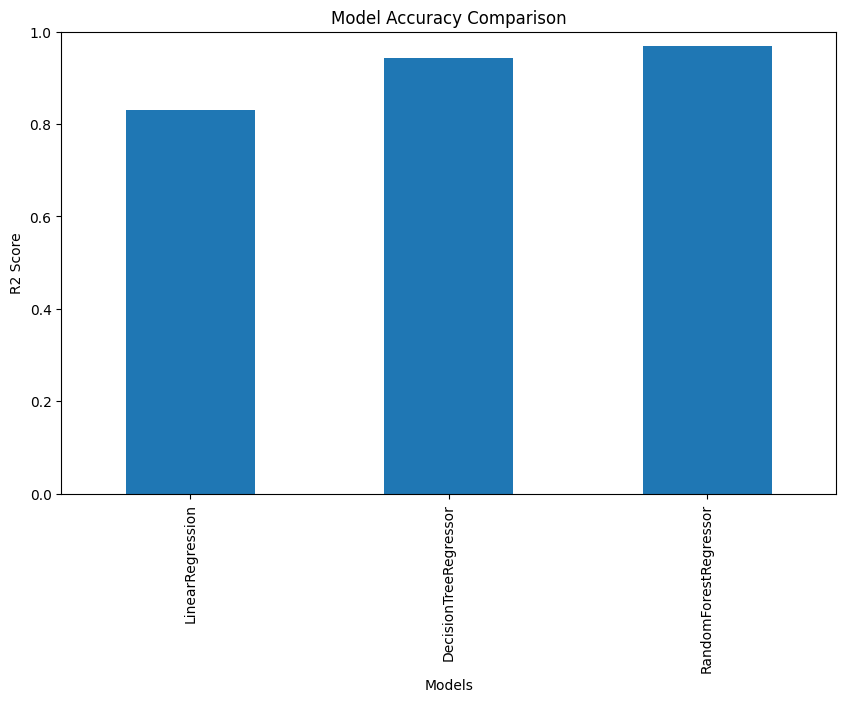

In [ ]:
results.set_index("Model")["R2 Score"].plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("Model Accuracy Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Models")
plt.ylim(0,1)
plt.show()

In [ ]:
results.set_index("Model")["Mean Absolute Error"].plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("Model Accuracy Comparison")
plt.ylabel("MA")
plt.xlabel("Models")
plt.ylim(0,1)
plt.show()